#¿Cómo puede una empresa minorista identificar riesgos de desabasto y optimizar sus decisiones de reabastecimiento utilizando datos históricos de ventas e inventario?

Una empresa con varias sucursales necesita identificar qué productos requieren reabastecimiento, cuáles tienen suficiente cobertura y dónde existe una posible acumulación de inventario.

Sin un análisis integrado, las decisiones de compra podrían basarse únicamente en ventas recientes o existencias disponibles, sin considerar el ritmo de consumo de cada producto.

##Objetivo general y objetivos específicos

###Objetivo general

Desarrollar una solución analítica que integre información histórica de ventas, inventario y demanda para identificar riesgos de desabasto, evaluar la cobertura de productos y generar recomendaciones de reabastecimiento para distintas sucursales.

###Objetivos específicos
1. Evaluar y preparar los datos, identificando anomalías que puedan afectar los indicadores.
2. Analizar el comportamiento histórico de la demanda por producto y sucursal.
3. Calcular indicadores de cobertura de inventario y estimar puntos de reorden.
4. Clasificar productos según su nivel de riesgo operativo.
5. Construir un dashboard que permita priorizar decisiones de reabastecimiento.

# Etapa 1. Exploración y evaluación de calidad de datos (EDA)

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

df = pd.read_csv("/content/retail_store_inventory.csv")

# Comprobar dimensiones
print("Dimensiones:", df.shape)

# Visualizar los primeros 5 registros
display(df.head())

Dimensiones: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df.tail()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring
73099,2024-01-01,S005,P0020,Groceries,East,117,6,165,2.33,78.39,20,Rainy,1,79.52,Spring


In [ ]:
df.columns.tolist()

['Date',
 'Store ID',
 'Product ID',
 'Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Demand Forecast',
 'Price',
 'Discount',
 'Weather Condition',
 'Holiday/Promotion',
 'Competitor Pricing',
 'Seasonality']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [ ]:
df.describe()

,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,holiday/promotion,competitor_pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


#Etapa 2. Limpieza y transformación de datos (Data Cleaning & ETL)

In [ ]:
# Estandarizar nombres de columnas
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# Verificar los cambios
print(df.columns.tolist())

['date', 'store_id', 'product_id', 'category', 'region', 'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast', 'price', 'discount', 'weather_condition', 'holiday/promotion', 'competitor_pricing', 'seasonality']


In [ ]:

# Nulos por columna
nulls = df.isna().sum().sort_values(ascending=False)

# Filas completamente duplicadas
duplicates = df.duplicated().sum()

print("Valores nulos:")
print(nulls)

print("\nFilas duplicadas:", duplicates)

# Validación de métricas operativas
print(
    "Ventas negativas:",
    (df["units_sold"] < 0).sum()
)

print(
    "Inventario negativo:",
    (df["inventory_level"] < 0).sum()
)

print(
    "Ventas mayores al inventario:",
    (df["units_sold"] > df["inventory_level"]).sum()
)

print(
    "Pronósticos negativos:",
    (df["demand_forecast"] < 0).sum()
)


Valores nulos:
date                  0
store_id              0
product_id            0
category              0
region                0
inventory_level       0
units_sold            0
units_ordered         0
demand_forecast       0
price                 0
discount              0
weather_condition     0
holiday/promotion     0
competitor_pricing    0
seasonality           0
dtype: int64

Filas duplicadas: 0
Ventas negativas: 0
Inventario negativo: 0
Ventas mayores al inventario: 0
Pronósticos negativos: 673


### Exploracion en Pronosticos negativos

Se profundizara en este punto para entender cual es la causa de los 673 pronosticos negativos antes de dar una conclusión, ya sea que esta se deba a una estacionalidad, que sea atipico o su se deba a la misma naturaleza del negocio por ejemplo.

In [ ]:
# Validación de métricas operativas
print( "Ventas negativas:",
    (df["units_sold"] < 0).sum())

Ventas negativas: 0


In [ ]:

# Convertir a fecha
df["date"] = pd.to_datetime(df["date"])

# Comprobar duplicados por clave operativa
key = ["date", "store_id", "product_id"]

print(
    "Duplicados por fecha, tienda y producto:",
    df.duplicated(subset=key).sum()
)

# Número de tiendas y productos
print("Tiendas:", df["store_id"].nunique())
print("Productos:", df["product_id"].nunique())

# Rango temporal
print("Primera fecha:", df["date"].min())
print("Última fecha:", df["date"].max())

# Estabilidad de atributos
print(
    "Productos con múltiples categorías:",
    (df.groupby("product_id")["category"].nunique() > 1).sum()
)

print(
    "Tiendas con múltiples regiones:",
    (df.groupby("store_id")["region"].nunique() > 1).sum()
)


Duplicados por fecha, tienda y producto: 0
Tiendas: 5
Productos: 20
Primera fecha: 2022-01-01 00:00:00
Última fecha: 2024-01-01 00:00:00
Productos con múltiples categorías: 20
Tiendas con múltiples regiones: 5


In [ ]:

# Filtrar registros con pronósticos negativos
negative_forecasts = df[df["demand_forecast"] < 0].copy()

# Estadísticas descriptivas
display(negative_forecasts["demand_forecast"].describe())

# Revisar ejemplos
display(
    negative_forecasts[
        ["date", "store_id", "product_id",
         "units_sold", "demand_forecast"]
    ].head(10)
)


,demand_forecast
count,673.000000
mean,-3.693730
std,2.535978
min,-9.990000
25%,-5.470000
50%,-3.380000
75%,-1.540000
max,-0.010000


,date,store_id,product_id,units_sold,demand_forecast
63,2022-01-01,S004,P0004,0,-2.40
141,2022-01-02,S003,P0002,2,-3.40
278,2022-01-03,S004,P0019,1,-3.91
511,2022-01-06,S001,P0012,1,-8.37
730,2022-01-08,S002,P0011,7,-2.99
844,2022-01-09,S003,P0005,4,-1.33
1011,2022-01-11,S001,P0012,3,-6.05
1107,2022-01-12,S001,P0008,0,-3.55
1149,2022-01-12,S003,P0010,6,-0.11
1180,2022-01-12,S005,P0001,6,-2.04


In [ ]:

# Convertir fechas
negative_forecasts["date"] = pd.to_datetime(
    negative_forecasts["date"]
)

# Extraer mes
negative_forecasts["month"] = (
    negative_forecasts["date"].dt.month
)

# Contar pronósticos negativos por mes
monthly_negative = (
    negative_forecasts
    .groupby("month")
    .size()
    .reset_index(name="negative_forecasts")
)

display(monthly_negative)


,month,negative_forecasts
0,1,59
1,2,52
2,3,51
3,4,59
4,5,52
5,6,62
6,7,67
7,8,48
8,9,66
9,10,57


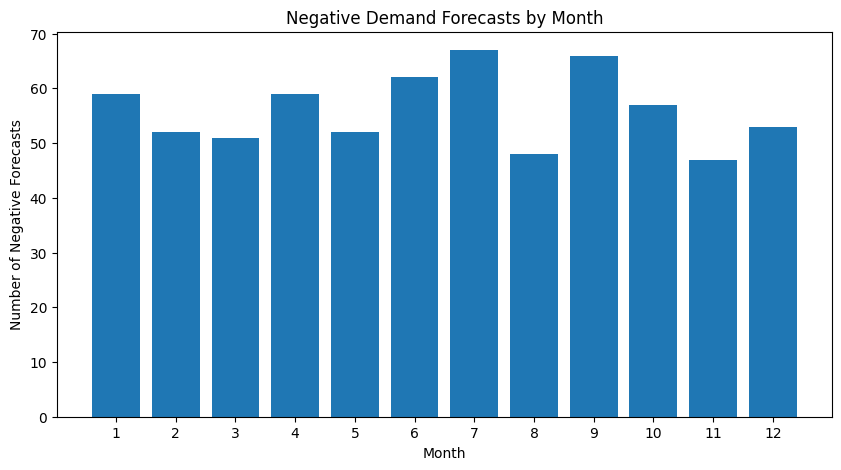

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_negative["month"],
    monthly_negative["negative_forecasts"]
)

plt.title("Negative Demand Forecasts by Month")
plt.xlabel("Month")
plt.ylabel("Number of Negative Forecasts")
plt.xticks(range(1, 13))
plt.show()


In [ ]:

# Contar negativos por producto
product_negative = (
    negative_forecasts
    .groupby("product_id")
    .size()
    .reset_index(name="negative_forecasts")
    .sort_values(
        "negative_forecasts",
        ascending=False
    )
)

display(product_negative.head(10))


,product_id,negative_forecasts
18,P0019,50
14,P0015,49
9,P0010,38
0,P0001,37
2,P0003,37
3,P0004,37
6,P0007,37
19,P0020,35
10,P0011,34
1,P0002,33


Productos P0019, P0015, P0010, Son aquellos que mantienen el top 3 con pronosticos negativos, aunque tampoco mantienen una varianza muy alejada entre los demas productos que se encuentran en esta posición

In [ ]:

# Comparar pronóstico negativo con ventas reales
comparison = negative_forecasts[
    ["units_sold", "demand_forecast"]
].describe()

display(comparison)

# Cuántos pronósticos negativos tuvieron ventas positivas
positive_sales = (
    negative_forecasts["units_sold"] > 0
).sum()

print(
    "Pronósticos negativos con ventas positivas:",
    positive_sales
)


,units_sold,demand_forecast
count,673.000000,673.000000
mean,2.912333,-3.693730
std,2.533651,2.535978
min,0.000000,-9.990000
25%,1.000000,-5.470000
50%,2.000000,-3.380000
75%,5.000000,-1.540000
max,9.000000,-0.010000


Pronósticos negativos con ventas positivas: 541


In [ ]:
# Preparar fechas
df["date"] = pd.to_datetime(df["date"])

# Crear variables temporales
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Identificar pronósticos negativos
df["negative_forecast"] = df["demand_forecast"] < 0

# Calcular incidencia mensual por año
monthly_analysis = (
    df.groupby(["year", "month"])
    .agg(
        total_records=("demand_forecast", "size"),
        negative_forecasts=("negative_forecast", "sum"),
        average_sales=("units_sold", "mean")
    )
    .reset_index()
)

# Porcentaje de pronósticos negativos
monthly_analysis["negative_rate_pct"] = (
    monthly_analysis["negative_forecasts"]
    / monthly_analysis["total_records"]
    * 100
)

display(monthly_analysis)


,year,month,total_records,negative_forecasts,average_sales,negative_rate_pct
0,2022,1,3100,26,135.463871,0.838710
1,2022,2,2800,26,139.661429,0.928571
2,2022,3,3100,17,137.442903,0.548387
3,2022,4,3000,25,135.793333,0.833333
4,2022,5,3100,26,133.806129,0.838710
5,2022,6,3000,26,138.503000,0.866667
6,2022,7,3100,33,137.621935,1.064516
7,2022,8,3100,24,137.069677,0.774194
8,2022,9,3000,31,137.203333,1.033333
9,2022,10,3100,22,137.697742,0.709677


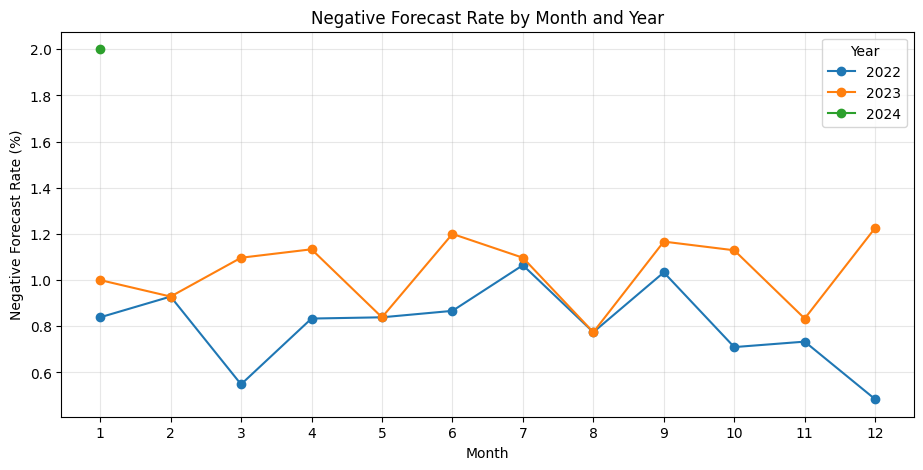

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

for year, data in monthly_analysis.groupby("year"):
    plt.plot(
        data["month"],
        data["negative_rate_pct"],
        marker="o",
        label=str(year)
    )

plt.title("Negative Forecast Rate by Month and Year")
plt.xlabel("Month")
plt.ylabel("Negative Forecast Rate (%)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Verificar cobertura temporal por año y mes
coverage = (
    df.groupby(["year", "month"])
    .agg(
        total_records=("demand_forecast", "size"),
        unique_days=("date", "nunique"),
        negative_forecasts=("negative_forecast", "sum")
    )
    .reset_index()
)

display(coverage)


,year,month,total_records,unique_days,negative_forecasts
0,2022,1,3100,31,26
1,2022,2,2800,28,26
2,2022,3,3100,31,17
3,2022,4,3000,30,25
4,2022,5,3100,31,26
5,2022,6,3000,30,26
6,2022,7,3100,31,33
7,2022,8,3100,31,24
8,2022,9,3000,30,31
9,2022,10,3100,31,22


Aqui estamos revisando enero del 2024 y ver porque se da el 2% en la grafica lineal en comparacion con los otros 2 años anteriores, y pudiera  deberser a los dias de informacion recabados en este dataset para esta exploracion, aunque no es una conclusión.

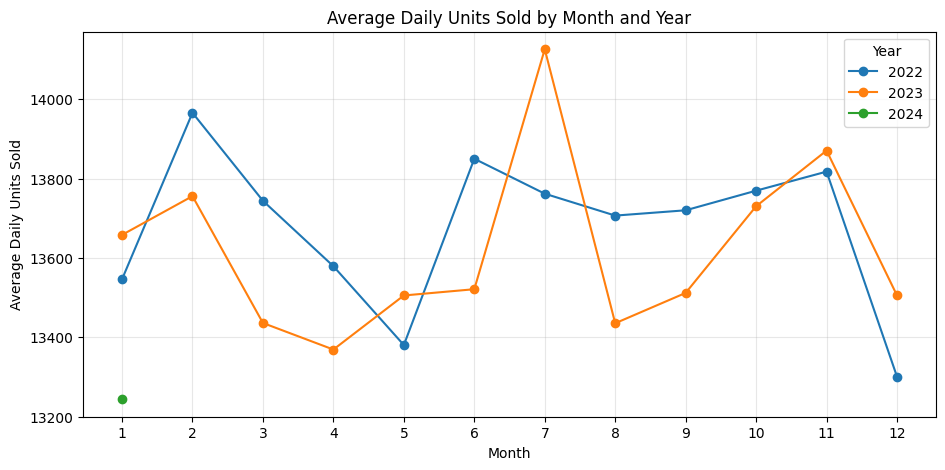

In [ ]:
# Calcular ventas diarias totales
daily_sales = (
    df.groupby("date", as_index=False)
    .agg(total_units_sold=("units_sold", "sum"))
)

daily_sales["year"] = daily_sales["date"].dt.year
daily_sales["month"] = daily_sales["date"].dt.month

# Promediar ventas diarias por mes y año
sales_seasonality = (
    daily_sales.groupby(["year", "month"])
    .agg(
        average_daily_sales=("total_units_sold", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))

for year, data in sales_seasonality.groupby("year"):
    plt.plot(
        data["month"],
        data["average_daily_sales"],
        marker="o",
        label=str(year)
    )

plt.title("Average Daily Units Sold by Month and Year")
plt.xlabel("Month")
plt.ylabel("Average Daily Units Sold")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()


Encontramos inconsistencias en los pronósticos de demanda que podrían comprometer la interpretación de indicadores operativos.

Sin embargo, no encontramos evidencia suficiente para concluir que las anomalías sean producto de la estacionalidad, por lo que sería incorrecto atribuirlas a cambios periódicos de la demanda.

Nuestra decisión provisional es conservar los valores originales, crear una versión ajustada para los indicadores operativos y documentar cada transformación.

Esto representa nuestro primer resultado de calidad de datos, pero todavía no es la solución principal del proyecto.

In [ ]:

# Conservar pronósticos originales
df["demand_forecast_original"] = df["demand_forecast"]

# Crear versión ajustada a un mínimo de cero
df["demand_forecast_adjusted"] = (
    df["demand_forecast"].clip(lower=0)
)

# Identificar registros ajustados
df["forecast_adjusted_flag"] = (
    df["demand_forecast"] < 0
).astype(int)

# Comprobar resultados
print(
    "Registros ajustados:",
    df["forecast_adjusted_flag"].sum()
)

print(
    "Pronósticos negativos restantes:",
    (df["demand_forecast_adjusted"] < 0).sum()
)


Registros ajustados: 673
Pronósticos negativos restantes: 0


Este ajuste no mejora automáticamente la precisión de los pronósticos. Solo establece un límite inferior razonable de cero. Por eso conservamos la variable original para futuras evaluaciones.

In [ ]:

# Crear dataset procesado
inventory_clean = df.copy()

# Exportar a CSV
inventory_clean.to_csv(
    "data/inventory_daily.csv",
    index=False
)

print("Dataset exportado correctamente")
print("Dimensiones:", inventory_clean.shape)


Dataset exportado correctamente
Dimensiones: (73100, 21)


In [ ]:
from google.colab import files

files.download("data/inventory_daily.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Etapa 3. Análisis de negocio con SQL (Business Analytics)

In [ ]:

# Crear copia del dataset procesado
inventory_clean = df.copy()

# Exportar archivo CSV
inventory_clean.to_csv(
    "data/inventory_daily.csv",
    index=False
)

print("Archivo exportado correctamente")
print("Dimensiones:", inventory_clean.shape)


Archivo exportado correctamente
Dimensiones: (73100, 21)


In [ ]:
%pip install -q duckdb

In [ ]:
import duckdb

# Crear conexión a DuckDB
con = duckdb.connect("inventory_analysis.duckdb")

print("Conexión establecida correctamente")

Conexión establecida correctamente


In [ ]:

con.execute("""
    CREATE OR REPLACE TABLE inventory_daily AS
    SELECT *
    FROM read_csv_auto('data/inventory_daily.csv')
""")

print("Tabla creada correctamente")


Tabla creada correctamente


In [ ]:

query = """
SELECT *
FROM inventory_daily
LIMIT 5
"""

display(con.execute(query).df())


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,...,weather_condition,holiday/promotion,competitor_pricing,seasonality,year,month,negative_forecast,demand_forecast_original,demand_forecast_adjusted,forecast_adjusted_flag
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,Rainy,0,29.69,Autumn,2022,1,False,135.47,135.47,0
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,...,Sunny,0,66.16,Autumn,2022,1,False,144.04,144.04,0
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,...,Sunny,1,31.32,Summer,2022,1,False,74.02,74.02,0
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,...,Cloudy,1,34.74,Autumn,2022,1,False,62.18,62.18,0
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,...,Sunny,0,68.95,Summer,2022,1,False,9.26,9.26,0


In [ ]:

query = """
SELECT
    COUNT(*) AS total_records,
    SUM(
        CASE
            WHEN demand_forecast_original < 0 THEN 1
            ELSE 0
        END
    ) AS original_negative_forecasts,
    SUM(
        CASE
            WHEN demand_forecast_adjusted < 0 THEN 1
            ELSE 0
        END
    ) AS adjusted_negative_forecasts
FROM inventory_daily
"""

display(con.execute(query).df())


,total_records,original_negative_forecasts,adjusted_negative_forecasts
0,73100,673.0,0.0


Validando que los datos se hayan pasado corretamente, donde mantenemos la variable "original_negative_forecasts" para entender que si

##Identificar los productos con mayor volumen de ventas

In [ ]:

query = """
SELECT
    product_id,
    SUM(units_sold) AS total_units_sold,
    ROUND(AVG(units_sold), 2) AS avg_units_sold,
    COUNT(*) AS total_records
FROM inventory_daily
GROUP BY product_id
ORDER BY total_units_sold DESC
LIMIT 20
"""

top_products = con.execute(query).df()

display(top_products)


,product_id,total_units_sold,avg_units_sold,total_records
0,P0016,508472.0,139.12,3655
1,P0020,507708.0,138.91,3655
2,P0014,507622.0,138.88,3655
3,P0015,507283.0,138.79,3655
4,P0005,503648.0,137.80,3655
5,P0009,502086.0,137.37,3655
6,P0013,500619.0,136.97,3655
7,P0017,500510.0,136.94,3655
8,P0011,499362.0,136.62,3655
9,P0007,499321.0,136.61,3655


Poca varianza entre ventas por producto

##Análisis de ventas por tienda

In [ ]:

query = """
SELECT
    store_id,
    SUM(units_sold) AS total_units_sold,
    ROUND(AVG(units_sold), 2) AS avg_units_sold,
    COUNT(*) AS total_records
FROM inventory_daily
GROUP BY store_id
ORDER BY total_units_sold DESC
"""

store_sales = con.execute(query).df()

display(store_sales)


,store_id,total_units_sold,avg_units_sold,total_records
0,S003,2022696.0,138.35,14620
1,S005,2010176.0,137.49,14620
2,S002,1987715.0,135.96,14620
3,S004,1979245.0,135.38,14620
4,S001,1975750.0,135.14,14620


Sigue existiendo poca varianza de ventas por sucursal

##Análisis por producto y tienda

In [ ]:

query = """
SELECT
    store_id,
    product_id,
    SUM(units_sold) AS total_units_sold,
    ROUND(AVG(units_sold), 2) AS avg_daily_units_sold,
    COUNT(*) AS total_records
FROM inventory_daily
GROUP BY store_id, product_id
ORDER BY avg_daily_units_sold DESC
"""

store_product_sales = con.execute(query).df()

display(store_product_sales.head(20))


,store_id,product_id,total_units_sold,avg_daily_units_sold,total_records
0,S005,P0015,109099.0,149.25,731
1,S003,P0013,107479.0,147.03,731
2,S002,P0001,105999.0,145.01,731
3,S005,P0003,105667.0,144.55,731
4,S003,P0005,105408.0,144.20,731
5,S002,P0009,105376.0,144.15,731
6,S002,P0020,105343.0,144.11,731
7,S003,P0014,105188.0,143.90,731
8,S004,P0016,104777.0,143.33,731
9,S003,P0017,104566.0,143.05,731


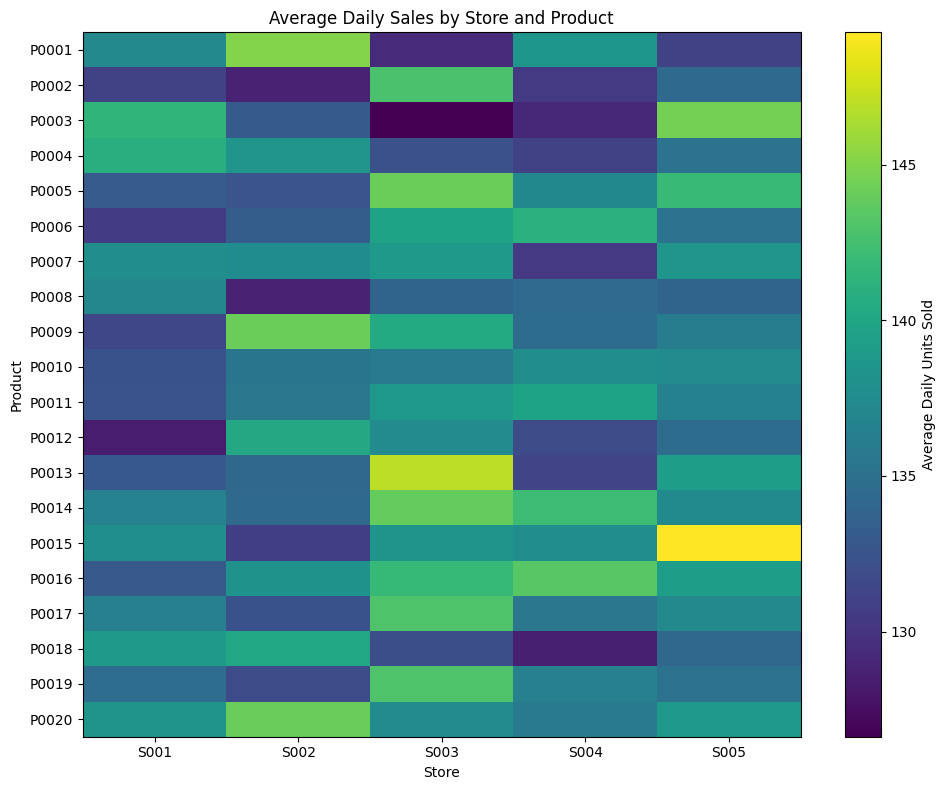

In [ ]:

import matplotlib.pyplot as plt

pivot_sales = store_product_sales.pivot(
    index="product_id",
    columns="store_id",
    values="avg_daily_units_sold"
)

plt.figure(figsize=(10, 8))

plt.imshow(pivot_sales, aspect="auto")
plt.colorbar(label="Average Daily Units Sold")

plt.xticks(
    range(len(pivot_sales.columns)),
    pivot_sales.columns
)

plt.yticks(
    range(len(pivot_sales.index)),
    pivot_sales.index
)

plt.xlabel("Store")
plt.ylabel("Product")
plt.title("Average Daily Sales by Store and Product")

plt.tight_layout()
plt.show()


Visualmente se alcanza a notar que hay combinaciones específicas que resaltan más que las demás.

La más evidente es:
- P0015 en S005
Y también se alcanzan a percibir otras relativamente altas, como por ejemplo:
- P0013 en S003
- P0014 en S003
- P0001 en S002
- P0020 en S002 / S005 (visualmente se ven elevadas)
No significa todavía que sean un “problema”, pero sí que la demanda no es completamente uniforme cuando bajamos la granularidad.

Aunque las ventas agregadas por producto y por sucursal muestran poca variación, el análisis a nivel de combinación producto-sucursal revela diferencias puntuales en la demanda promedio diaria. Esto sugiere que el riesgo operativo no debe evaluarse a nivel agregado, sino a nivel de SKU por sucursal.

Aún no podemos decir:
- que P0015 en S005 sea el caso más crítico,
- ni que sea una prioridad de reabastecimiento,
porque todavía no hemos comparado esa demanda con su inventario disponible.

##Validacion de categorías y regiones consistentes

In [ ]:

query = """
SELECT
    product_id,
    COUNT(DISTINCT category) AS total_categories
FROM inventory_daily
GROUP BY product_id
HAVING COUNT(DISTINCT category) > 1
ORDER BY total_categories DESC
"""

display(con.execute(query).df())


,product_id,total_categories
0,P0002,5
1,P0018,5
2,P0020,5
3,P0003,5
4,P0008,5
5,P0012,5
6,P0017,5
7,P0004,5
8,P0010,5
9,P0001,5


In [ ]:

query = """
SELECT
    store_id,
    COUNT(DISTINCT region) AS total_regions
FROM inventory_daily
GROUP BY store_id
HAVING COUNT(DISTINCT region) > 1
ORDER BY total_regions DESC
"""

display(con.execute(query).df())


,store_id,total_regions
0,S005,4
1,S001,4
2,S002,4
3,S003,4
4,S004,4


Hasta ahora hemos observado:
- Ventas similares entre los 20 productos.
- Ventas similares entre las cinco sucursales.
- Ausencia de un patrón estacional claramente consistente.
- Anomalías en los pronósticos que ya identificamos y tratamos.

##Demanda por producto y sucursal

In [ ]:

query = """
SELECT
    store_id,
    product_id,
    ROUND(AVG(units_sold), 2) AS avg_daily_units_sold,
    MIN(units_sold) AS min_units_sold,
    MAX(units_sold) AS max_units_sold,
    ROUND(STDDEV_SAMP(units_sold), 2) AS std_units_sold,
    COUNT(*) AS total_records
FROM inventory_daily
GROUP BY store_id, product_id
ORDER BY avg_daily_units_sold DESC
"""

store_product_analysis = con.execute(query).df()

display(store_product_analysis.head(20))


,store_id,product_id,avg_daily_units_sold,min_units_sold,max_units_sold,std_units_sold,total_records
0,S005,P0015,149.25,0,461,115.68,731
1,S003,P0013,147.03,0,486,112.60,731
2,S002,P0001,145.01,0,474,113.57,731
3,S005,P0003,144.55,0,474,111.93,731
4,S003,P0005,144.20,0,478,109.34,731
5,S002,P0009,144.15,0,476,112.42,731
6,S002,P0020,144.11,0,479,113.54,731
7,S003,P0014,143.90,0,481,113.02,731
8,S004,P0016,143.33,0,465,107.70,731
9,S003,P0017,143.05,0,495,107.78,731


##Calculo de cobertura de inventario

In [ ]:
query = """
WITH max_date AS (
    SELECT MAX(date) AS latest_date
    FROM inventory_daily
),

last_30_days_demand AS (
    SELECT
        store_id,
        product_id,
        ROUND(AVG(units_sold), 2) AS avg_daily_demand_30d
    FROM inventory_daily, max_date
    WHERE date >= latest_date - INTERVAL 29 DAY
    GROUP BY store_id, product_id
),

latest_inventory AS (
    SELECT
        store_id,
        product_id,
        inventory_level,
        date,
        ROW_NUMBER() OVER (
            PARTITION BY store_id, product_id
            ORDER BY date DESC
        ) AS rn
    FROM inventory_daily
),

current_inventory AS (
    SELECT
        store_id,
        product_id,
        inventory_level AS current_inventory
    FROM latest_inventory
    WHERE rn = 1
),

inventory_coverage AS (
    SELECT
        d.store_id,
        d.product_id,
        d.avg_daily_demand_30d,
        c.current_inventory,
        CASE
            WHEN d.avg_daily_demand_30d = 0 THEN NULL
            ELSE ROUND(c.current_inventory / d.avg_daily_demand_30d, 2)
        END AS days_of_coverage
    FROM last_30_days_demand d
    LEFT JOIN current_inventory c
        ON d.store_id = c.store_id
       AND d.product_id = c.product_id
)

SELECT *
FROM inventory_coverage
ORDER BY days_of_coverage ASC
LIMIT 20
"""
coverage_df = con.execute(query).df()
display(coverage_df)

,store_id,product_id,avg_daily_demand_30d,current_inventory,days_of_coverage
0,S002,P0007,168.63,53,0.31
1,S002,P0009,158.07,62,0.39
2,S005,P0007,129.83,59,0.45
3,S004,P0015,123.37,56,0.45
4,S001,P0016,150.80,74,0.49
5,S001,P0003,139.10,69,0.50
6,S004,P0019,102.77,65,0.63
7,S004,P0017,154.57,100,0.65
8,S005,P0003,140.83,98,0.70
9,S004,P0009,163.00,115,0.71


In [ ]:
query = """
WITH max_date AS (
    SELECT MAX(date) AS latest_date
    FROM inventory_daily
),

last_30_days_demand AS (
    SELECT
        store_id,
        product_id,
        ROUND(AVG(units_sold), 2) AS avg_daily_demand_30d
    FROM inventory_daily, max_date
    WHERE date >= latest_date - INTERVAL 29 DAY
    GROUP BY store_id, product_id
),

latest_inventory AS (
    SELECT
        store_id,
        product_id,
        inventory_level,
        date,
        ROW_NUMBER() OVER (
            PARTITION BY store_id, product_id
            ORDER BY date DESC
        ) AS rn
    FROM inventory_daily
),

current_inventory AS (
    SELECT
        store_id,
        product_id,
        inventory_level AS current_inventory
    FROM latest_inventory
    WHERE rn = 1
)

SELECT
    d.store_id,
    d.product_id,
    d.avg_daily_demand_30d,
    c.current_inventory,
    CASE
        WHEN d.avg_daily_demand_30d = 0 THEN NULL
        ELSE ROUND(c.current_inventory / d.avg_daily_demand_30d, 2)
    END AS days_of_coverage,
    CASE
        WHEN d.avg_daily_demand_30d = 0 THEN 'No Demand'
        WHEN c.current_inventory / d.avg_daily_demand_30d <= 3 THEN 'Critical'
        WHEN c.current_inventory / d.avg_daily_demand_30d <= 7 THEN 'High'
        WHEN c.current_inventory / d.avg_daily_demand_30d <= 14 THEN 'Moderate'
        ELSE 'Normal'
    END AS replenishment_priority
FROM last_30_days_demand d
LEFT JOIN current_inventory c
    ON d.store_id = c.store_id
   AND d.product_id = c.product_id
ORDER BY days_of_coverage ASC
LIMIT 20
"""
priority_df = con.execute(query).df()
display(priority_df)

,store_id,product_id,avg_daily_demand_30d,current_inventory,days_of_coverage,replenishment_priority
0,S002,P0007,168.63,53,0.31,Critical
1,S002,P0009,158.07,62,0.39,Critical
2,S005,P0007,129.83,59,0.45,Critical
3,S004,P0015,123.37,56,0.45,Critical
4,S001,P0016,150.80,74,0.49,Critical
5,S001,P0003,139.10,69,0.50,Critical
6,S004,P0019,102.77,65,0.63,Critical
7,S004,P0017,154.57,100,0.65,Critical
8,S005,P0003,140.83,98,0.70,Critical
9,S004,P0009,163.00,115,0.71,Critical


Estos resultados muestran que las existencias registradas representan menos de un día de ventas promedio recientes para esas combinaciones.

Pero hay una distinción importante: como usamos ORDER BY days_of_coverage ASC LIMIT 20, estamos viendo únicamente los 20 registros de menor cobertura. Que todos sean críticos no significa que todas las combinaciones del dataset lo sean.

Además, estamos utilizando el último inventario registrado y las ventas recientes. Estas métricas son una estimación de cobertura, no una confirmación de que vaya a producirse un desabasto.

Ya estamos en condiciones de profundizar en tres preguntas concretas:
###1. ¿Qué proporción de los 100 pares tienda-producto presenta riesgo crítico o alto?
###2. ¿Qué sucursales concentran más productos con baja cobertura?
###3. ¿Cuánto inventario adicional se necesitaría para alcanzar una cobertura objetivo?

La tercera pregunta es especialmente relevante porque transforma el análisis en una recomendación operativa cuantificable.

In [ ]:
# Eliminar el límite de filas de la consulta
query_all = query.replace("LIMIT 20", "")

# Ejecutar sobre las 100 combinaciones
priority_all = con.execute(query_all).df()

print("Total de combinaciones:", len(priority_all))

display(priority_all.head())

Total de combinaciones: 100


,store_id,product_id,avg_daily_demand_30d,current_inventory,days_of_coverage,replenishment_priority
0,S002,P0007,168.63,53,0.31,Critical
1,S002,P0009,158.07,62,0.39,Critical
2,S005,P0007,129.83,59,0.45,Critical
3,S004,P0015,123.37,56,0.45,Critical
4,S001,P0016,150.80,74,0.49,Critical


##Distribución de prioridades

In [ ]:

priority_summary = (
    priority_all
    .groupby("replenishment_priority")
    .agg(
        product_store_count=("product_id", "count"),
        average_coverage=("days_of_coverage", "mean")
    )
    .reset_index()
)

priority_summary["percentage"] = (
    priority_summary["product_store_count"]
    / len(priority_all)
    * 100
)

display(priority_summary)


,replenishment_priority,product_store_count,average_coverage,percentage
0,Critical,84,1.687500,84.0
1,High,16,3.414375,16.0


##¿Qué sucursales concentran más productos críticos?

In [ ]:

store_risk = (
    priority_all
    .groupby("store_id")
    .agg(
        total_products=("product_id", "count"),
        critical_products=(
            "replenishment_priority",
            lambda x: (x == "Critical").sum()
        ),
        average_coverage=("days_of_coverage", "mean")
    )
    .reset_index()
)

store_risk["critical_rate_pct"] = (
    store_risk["critical_products"]
    / store_risk["total_products"]
    * 100
)

display(
    store_risk.sort_values(
        "critical_rate_pct",
        ascending=False
    )
)


,store_id,total_products,critical_products,average_coverage,critical_rate_pct
0,S001,20,20,1.9010,100.0
4,S005,20,18,2.0995,90.0
1,S002,20,16,2.0665,80.0
3,S004,20,16,1.6850,80.0
2,S003,20,14,2.0670,70.0


##Gráfica: porcentaje de productos críticos por sucursal

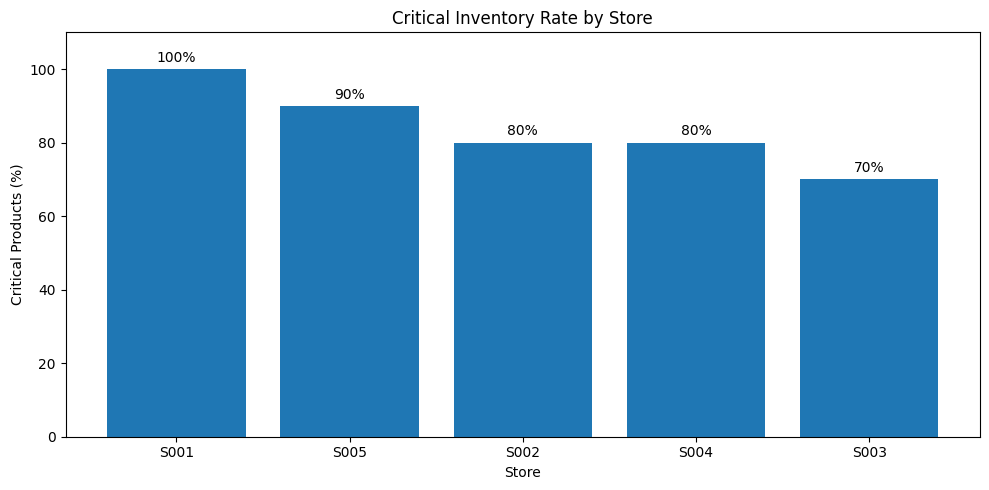

In [ ]:

import matplotlib.pyplot as plt

# Ordenar sucursales por porcentaje crítico
store_risk_plot = store_risk.sort_values(
    "critical_rate_pct",
    ascending=False
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    store_risk_plot["store_id"],
    store_risk_plot["critical_rate_pct"]
)

plt.title("Critical Inventory Rate by Store")
plt.xlabel("Store")
plt.ylabel("Critical Products (%)")
plt.ylim(0, 110)

# Etiquetas de porcentaje
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.0f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


El porcentaje de productos críticos por sucursal nos indica qué proporción de los productos de una tienda tiene un nivel de inventario considerado insuficiente según los criterios que establecimos.

En nuestro proyecto , clasificamos como crítico a cualquier producto cuya cobertura de inventario sea de 3 días o menos.

##Gráfica: cobertura promedio de inventario

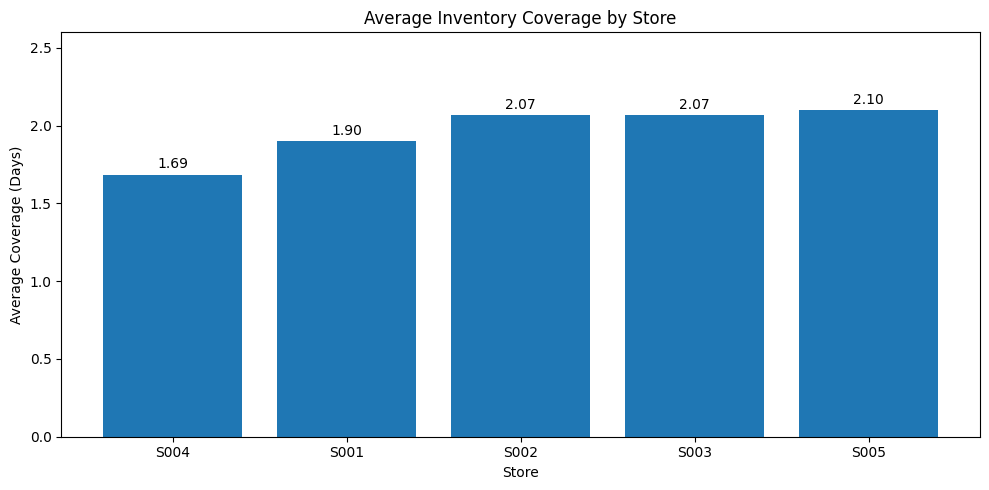

In [ ]:

# Ordenar de menor a mayor cobertura
coverage_plot = store_risk.sort_values(
    "average_coverage"
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    coverage_plot["store_id"],
    coverage_plot["average_coverage"]
)

plt.title("Average Inventory Coverage by Store")
plt.xlabel("Store")
plt.ylabel("Average Coverage (Days)")
plt.ylim(0, 2.6)

# Etiquetas de cobertura
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.04,
        f"{height:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


###La cobertura promedio de inventario nos indica cuántos días, en promedio, podría durar el inventario disponible de los productos de una sucursal si las ventas continúan al ritmo observado.

### Historial de inventario y pedidos — Últimos 15 días

Para visualizar los niveles de inventario, unidades vendidas, unidades pedidas y pronósticos de demanda del producto P0007 en la sucursal S002, durante los últimos 15 días registrados.

In [ ]:

query = """
SELECT
    date,
    store_id,
    product_id,
    inventory_level,
    units_sold,
    units_ordered,
    demand_forecast_adjusted
FROM inventory_daily
WHERE store_id = 'S002'
  AND product_id = 'P0007'
ORDER BY date DESC
LIMIT 15
"""

inventory_history = con.execute(query).df()

display(inventory_history)


,date,store_id,product_id,inventory_level,units_sold,units_ordered,demand_forecast_adjusted
0,2024-01-01,S002,P0007,53,2,40,0.00
1,2023-12-31,S002,P0007,145,16,125,34.06
2,2023-12-30,S002,P0007,127,13,101,13.36
3,2023-12-29,S002,P0007,325,255,108,271.61
4,2023-12-28,S002,P0007,462,346,180,342.78
5,2023-12-27,S002,P0007,260,35,61,36.18
6,2023-12-26,S002,P0007,378,308,178,324.18
7,2023-12-25,S002,P0007,247,122,131,116.35
8,2023-12-24,S002,P0007,247,221,59,226.30
9,2023-12-23,S002,P0007,485,458,158,473.08


Primero se revisa cual es el comportamiento de este producto y tienda especificamente para poder replicar una vez que se pueda observar su comportamientos a los 100 productos en general

### Movimientos diarios de inventario — Análisis de variaciones

In [ ]:

query = """
WITH inventory_movements AS (
    SELECT
        date,
        store_id,
        product_id,
        inventory_level,
        units_sold,
        units_ordered,

        LAG(inventory_level) OVER (
            PARTITION BY store_id, product_id
            ORDER BY date
        ) AS previous_inventory

    FROM inventory_daily
)

SELECT
    date,
    inventory_level,
    previous_inventory,
    units_sold,
    units_ordered,

    inventory_level - previous_inventory
        AS inventory_change

FROM inventory_movements
WHERE store_id = 'S002'
  AND product_id = 'P0007'
  AND previous_inventory IS NOT NULL
ORDER BY date DESC
LIMIT 15
"""

inventory_movements = con.execute(query).df()

display(inventory_movements)


,date,inventory_level,previous_inventory,units_sold,units_ordered,inventory_change
0,2024-01-01,53,145,2,40,-92
1,2023-12-31,145,127,16,125,18
2,2023-12-30,127,325,13,101,-198
3,2023-12-29,325,462,255,108,-137
4,2023-12-28,462,260,346,180,202
5,2023-12-27,260,378,35,61,-118
6,2023-12-26,378,247,308,178,131
7,2023-12-25,247,247,122,131,0
8,2023-12-24,247,485,221,59,-238
9,2023-12-23,485,372,458,158,113


Antes de evaluar las 100 combinaciones, vamos a comprobar si los movimientos diarios son compatibles con una relación básica de inventario.

En una operación simplificada:
\[
{Inventario final} =
{Inventario inicial} +
{Entradas} -
{Salidas}
\]

Si inventory_level representa existencias al cierre y units_sold son las únicas salidas, podemos estimar las entradas netas necesarias para explicar cada cambio:
\[
{Entradas netas implícitas} =
{Variación de inventario} +
{Unidades vendidas}
\]

Este cálculo no demuestra que dichas entradas hayan ocurrido; únicamente nos permite comprobar la consistencia bajo ese supuesto.

In [ ]:

# Crear copia de la tabla de movimientos
inventory_validation = inventory_movements.copy()

# Estimar entradas netas implícitas
inventory_validation["implied_net_inflow"] = (
    inventory_validation["inventory_change"]
    + inventory_validation["units_sold"]
)

# Comparar contra unidades ordenadas
inventory_validation["inflow_order_difference"] = (
    inventory_validation["implied_net_inflow"]
    - inventory_validation["units_ordered"]
)

display(
    inventory_validation[
        [
            "date",
            "inventory_change",
            "units_sold",
            "units_ordered",
            "implied_net_inflow",
            "inflow_order_difference"
        ]
    ]
)


,date,inventory_change,units_sold,units_ordered,implied_net_inflow,inflow_order_difference
0,2024-01-01,-92,2,40,-90,-130
1,2023-12-31,18,16,125,34,-91
2,2023-12-30,-198,13,101,-185,-286
3,2023-12-29,-137,255,108,118,10
4,2023-12-28,202,346,180,548,368
5,2023-12-27,-118,35,61,-83,-144
6,2023-12-26,131,308,178,439,261
7,2023-12-25,0,122,131,122,-9
8,2023-12-24,-238,221,59,-17,-76
9,2023-12-23,113,458,158,571,413


implied_net_inflow:	Entradas netas que serían necesarias para explicar el cambio de inventario, suponiendo que las ventas son las únicas salidas.

inflow_order_difference:	Diferencia entre esas entradas netas estimadas y las unidades ordenadas.

### Análisis de consistencia de inventarios y pedidos

**Objetivo del análisis**

Evaluar la relación entre las variaciones diarias del inventario, las unidades vendidas y las unidades ordenadas, utilizando como caso exploratorio el producto P0007 en la sucursal S002.

**Metodología**

Se analizaron los últimos 15 registros diarios mediante SQL, utilizando la función `LAG()` para recuperar el inventario del día anterior y calcular la variación de existencias.

Posteriormente, se estimaron las entradas netas implícitas bajo el supuesto simplificado de que las ventas representan las únicas salidas del inventario:

Entradas netas implícitas = Variación del inventario + Unidades vendidas.

Finalmente, se compararon estas cantidades con las unidades ordenadas.

**Observaciones verificadas**

- Se identificaron tanto aumentos como disminuciones en los niveles diarios de inventario.
- Las entradas netas implícitas no coinciden sistemáticamente con las unidades ordenadas en el mismo día.
- El 28 de diciembre de 2023, las entradas netas implícitas fueron de 548 unidades, frente a 180 unidades ordenadas.
- El 1 de enero de 2024, se obtuvo una entrada neta implícita de -90 unidades, valor que no puede interpretarse como una recepción física de mercancía.

**Limitaciones**

El dataset no especifica cuándo se reciben los pedidos ni proporciona información suficiente sobre transferencias, devoluciones, pérdidas o ajustes de inventario.

Por ello, las diferencias observadas no permiten concluir que existan errores operativos o problemas reales de abastecimiento.

**Conclusión metodológica**

El análisis exploratorio no permitió conciliar completamente las variaciones diarias del inventario con las ventas y las órdenes registradas bajo los supuestos utilizados.

En consecuencia, las unidades ordenadas no se considerarán equivalentes a mercancía recibida y no se incorporarán directamente al inventario disponible sin información adicional.

Esta conclusión corresponde únicamente al caso exploratorio P0007–S002; todavía no se ha comprobado si el comportamiento se repite en las demás combinaciones producto-sucursal.

##Validación general de movimientos de inventario

In [ ]:

query = """
WITH inventory_movements AS (
    SELECT
        date,
        store_id,
        product_id,
        inventory_level,
        units_sold,
        units_ordered,

        LAG(inventory_level) OVER (
            PARTITION BY store_id, product_id
            ORDER BY date
        ) AS previous_inventory

    FROM inventory_daily
),

inventory_validation AS (
    SELECT
        *,
        inventory_level - previous_inventory
            AS inventory_change,

        inventory_level - previous_inventory
            + units_sold
            AS implied_net_inflow

    FROM inventory_movements
    WHERE previous_inventory IS NOT NULL
)

SELECT
    COUNT(*) AS total_movements,

    COUNT(
        CASE WHEN implied_net_inflow < 0 THEN 1 END
    ) AS negative_implied_inflows,

    COUNT(
        CASE WHEN implied_net_inflow != units_ordered
        THEN 1 END
    ) AS unmatched_orders,

    ROUND(AVG(implied_net_inflow), 2)
        AS avg_implied_inflow

FROM inventory_validation
"""

inventory_validation_summary = con.execute(query).df()

display(inventory_validation_summary)


,total_movements,negative_implied_inflows,unmatched_orders,avg_implied_inflow
0,73000,22986,72902,136.43


### Validación general del comportamiento de inventarios y pedidos

**Objetivo**

Comprobar si los cambios diarios en el inventario pueden explicarse a partir de las unidades vendidas y las unidades ordenadas.

**Análisis realizado**

Se analizaron 73,000 movimientos de inventario, correspondientes a 20 productos distribuidos en 5 sucursales.

Para cada producto y sucursal, comparamos el inventario de un día con el anterior y calculamos cuántas unidades adicionales serían necesarias para explicar el cambio, considerando las ventas registradas.

Después, comparamos estos resultados con las unidades ordenadas durante el mismo día.

**Resultados**

- **31.49% de los movimientos (22,986):** presentaron disminuciones de inventario que no pueden explicarse únicamente con las ventas, bajo el cálculo utilizado.
- **99.87% de los movimientos (72,902):** las entradas de inventario estimadas no coincidieron con las unidades ordenadas el mismo día.
- **136.43 unidades:** fue el promedio de las entradas netas estimadas mediante el cálculo.

**Interpretación**

Las variaciones de inventario no pueden explicarse completamente utilizando solamente las ventas y los pedidos del mismo día.

Esto podría deberse a que los pedidos se reciben en fechas posteriores o a que existen otros movimientos de mercancía que no están registrados en el dataset.

Sin embargo, no contamos con información suficiente para confirmar estas explicaciones.

**Conclusión**

El análisis permitió identificar una limitación en la información disponible: no conocemos cuándo se reciben los pedidos ni todos los movimientos que afectan las existencias.

Por esta razón, no utilizaremos las unidades ordenadas como si fueran mercancía disponible.

Para continuar con el análisis de cobertura, utilizaremos el inventario registrado y la demanda histórica, aclarando que los resultados representan estimaciones sujetas a estas limitaciones.

## Escenarios de reabastecimiento

Calcularemos las unidades adicionales necesarias para alcanzar una cobertura de inventario de 1, 3 y 7 días, considerando la demanda diaria promedio y el inventario disponible de cada producto y sucursal.

In [ ]:

import numpy as np

# Crear copia de nuestros resultados
replenishment = priority_all.copy()

# Escenarios de cobertura
coverage_scenarios = [1, 3, 7]

# Calcular unidades adicionales por escenario
for days in coverage_scenarios:

    replenishment[f"reorder_{days}d"] = np.maximum(
        0,
        np.ceil(
            replenishment["avg_daily_demand_30d"] * days
            - replenishment["current_inventory"]
        )
    ).astype(int)

# Visualizar resultados
display(
    replenishment[
        [
            "store_id",
            "product_id",
            "avg_daily_demand_30d",
            "current_inventory",
            "days_of_coverage",
            "reorder_1d",
            "reorder_3d",
            "reorder_7d"
        ]
    ].head(10)
)


,store_id,product_id,avg_daily_demand_30d,current_inventory,days_of_coverage,reorder_1d,reorder_3d,reorder_7d
0,S002,P0007,168.63,53,0.31,116,453,1128
1,S002,P0009,158.07,62,0.39,97,413,1045
2,S005,P0007,129.83,59,0.45,71,331,850
3,S004,P0015,123.37,56,0.45,68,315,808
4,S001,P0016,150.80,74,0.49,77,379,982
5,S001,P0003,139.10,69,0.50,71,349,905
6,S004,P0019,102.77,65,0.63,38,244,655
7,S004,P0017,154.57,100,0.65,55,364,982
8,S005,P0003,140.83,98,0.70,43,325,888
9,S004,P0009,163.00,115,0.71,48,374,1026


## Cálculo de unidades adicionales por producto y sucursal

Se estiman las unidades necesarias para alcanzar coberturas de 1, 3 y 7 días en las 100 combinaciones de productos y sucursales. Se muestran las primeras 10 filas para revisar los cálculos.

In [ ]:

# Resumen de necesidades por escenario
scenario_summary = replenishment[
    ["reorder_1d", "reorder_3d", "reorder_7d"]
].sum().to_frame(name="total_additional_units")

display(scenario_summary)

# Validar que las necesidades no sean negativas
assert (
    replenishment[
        ["reorder_1d", "reorder_3d", "reorder_7d"]
    ] >= 0
).all().all()

# Validar que aumenten con la cobertura objetivo
assert (
    (replenishment["reorder_1d"] <= replenishment["reorder_3d"])
    &
    (replenishment["reorder_3d"] <= replenishment["reorder_7d"])
).all()

print("Validaciones completadas")


,total_additional_units
reorder_1d,885
reorder_3d,15064
reorder_7d,68493


Validaciones completadas


### Resumen general de escenarios de reabastecimiento

Se suman las unidades adicionales calculadas para las 100 combinaciones, obteniendo el total requerido para cada escenario. También se valida que los resultados no sean negativos y aumenten conforme crece la cobertura objetivo.

## Comparación de necesidades de reabastecimiento por sucursal

Se agrupan las unidades adicionales estimadas por sucursal para comparar las necesidades de inventario bajo escenarios de cobertura de 1, 3 y 7 días.

In [ ]:

# Agrupar necesidades de inventario por sucursal
store_replenishment = (
    replenishment
    .groupby("store_id")
    .agg(
        reorder_1d=("reorder_1d", "sum"),
        reorder_3d=("reorder_3d", "sum"),
        reorder_7d=("reorder_7d", "sum")
    )
    .reset_index()
)

display(store_replenishment)


,store_id,reorder_1d,reorder_3d,reorder_7d
0,S001,148,3021,13881
1,S002,219,3045,13935
2,S003,77,2702,13291
3,S004,264,3619,13856
4,S005,177,2677,13530


### Comparación de escenarios por sucursal

Se compararon las unidades adicionales estimadas para las cinco sucursales. Las necesidades varían según la cobertura objetivo, permitiendo identificar qué tiendas requieren más unidades en cada escenario.

##Priorización de reabastecimiento por producto y sucursal

Se ordenan las combinaciones de productos y sucursales según su cobertura actual y se muestran las unidades adicionales necesarias para alcanzar una cobertura de 3 días.

In [ ]:

# Priorizar combinaciones con menor cobertura
replenishment_ranking = (
    replenishment[
        [
            "store_id",
            "product_id",
            "days_of_coverage",
            "current_inventory",
            "avg_daily_demand_30d",
            "reorder_3d"
        ]
    ]
    .sort_values(
        by=["days_of_coverage", "reorder_3d"],
        ascending=[True, False],
        na_position="last"
    )
    .reset_index(drop=True)
)

# Agregar posición en el ranking
replenishment_ranking.insert(
    0,
    "priority_rank",
    range(1, len(replenishment_ranking) + 1)
)

display(replenishment_ranking.head(15))


,priority_rank,store_id,product_id,days_of_coverage,current_inventory,avg_daily_demand_30d,reorder_3d
0,1,S002,P0007,0.31,53,168.63,453
1,2,S002,P0009,0.39,62,158.07,413
2,3,S005,P0007,0.45,59,129.83,331
3,4,S004,P0015,0.45,56,123.37,315
4,5,S001,P0016,0.49,74,150.80,379
5,6,S001,P0003,0.50,69,139.10,349
6,7,S004,P0019,0.63,65,102.77,244
7,8,S004,P0017,0.65,100,154.57,364
8,9,S005,P0003,0.70,98,140.83,325
9,10,S004,P0009,0.71,115,163.00,374


### Revisión del ranking de reabastecimiento

Se ordenaron las 100 combinaciones de producto y sucursal según sus días de cobertura, dando prioridad a las de menor duración estimada de inventario. Como criterio secundario, se utilizaron las unidades adicionales necesarias para alcanzar una cobertura de 3 días.

#Etapa 4. Preparación de datos para Tableau Public

### Validación de tablas para el dashboard

Se verifica que las tablas finales contengan las combinaciones esperadas de productos y sucursales, sin registros duplicados, antes de utilizarlas en Tableau.

In [ ]:

# Comprobar dimensiones
print("Ranking:", replenishment_ranking.shape)
print("Riesgo por sucursal:", store_risk.shape)
print("Reabastecimiento por sucursal:", store_replenishment.shape)

# Verificar duplicados en el ranking
duplicates = replenishment_ranking.duplicated(
    subset=["store_id", "product_id"]
).sum()

print("Combinaciones duplicadas:", duplicates)

# Validar las 100 combinaciones
assert len(replenishment_ranking) == 100
assert duplicates == 0

print("Validaciones completadas")


Ranking: (100, 7)
Riesgo por sucursal: (5, 5)
Reabastecimiento por sucursal: (5, 4)
Combinaciones duplicadas: 0
Validaciones completadas


¿Qué significa cada resultado?
- Ranking (100, 7): tenemos 100 combinaciones de producto y sucursal, con 7 columnas de información.
- Riesgo por sucursal (5, 5): tenemos 5 sucursales y 5 columnas con sus indicadores de riesgo.
- Reabastecimiento por sucursal (5, 4): tenemos 5 sucursales y 4 columnas: store_id, reorder_1d, reorder_3d y reorder_7d.

### Integración de indicadores para Tableau

Se consolidan los indicadores de demanda, cobertura, prioridad y necesidades de reabastecimiento en una tabla por producto y sucursal.

In [ ]:

# Crear tabla principal para Tableau
dashboard_data = replenishment.merge(
    replenishment_ranking[
        ["store_id", "product_id", "priority_rank"]
    ],
    on=["store_id", "product_id"],
    how="left",
    validate="one_to_one"
)

# Revisar estructura
print("Dimensiones:", dashboard_data.shape)

display(dashboard_data.head())


Dimensiones: (100, 10)


,store_id,product_id,avg_daily_demand_30d,current_inventory,days_of_coverage,replenishment_priority,reorder_1d,reorder_3d,reorder_7d,priority_rank
0,S002,P0007,168.63,53,0.31,Critical,116,453,1128,1
1,S002,P0009,158.07,62,0.39,Critical,97,413,1045,2
2,S005,P0007,129.83,59,0.45,Critical,71,331,850,3
3,S004,P0015,123.37,56,0.45,Critical,68,315,808,4
4,S001,P0016,150.80,74,0.49,Critical,77,379,982,5


### Exportación de datos para Tableau

Se exportan las tablas finales en formato CSV para construir el dashboard de inventarios y reabastecimiento.

In [ ]:

# Exportar tablas

dashboard_data.to_csv(
    "data/inventory_dashboard.csv",
    index=False
)

store_risk.to_csv(
    "data/store_risk.csv",
    index=False
)

store_replenishment.to_csv(
    "data/store_replenishment.csv",
    index=False
)

print("Archivos exportados correctamente")


Archivos exportados correctamente


In [ ]:
from google.colab import files

files.download("data/inventory_dashboard.csv")
files.download("data/store_risk.csv")
files.download("data/store_replenishment.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(store_risk.columns.tolist())

['store_id', 'total_products', 'critical_products', 'average_coverage', 'critical_rate_pct']


In [ ]:
print(store_replenishment.columns.tolist())

['store_id', 'reorder_1d', 'reorder_3d', 'reorder_7d']
